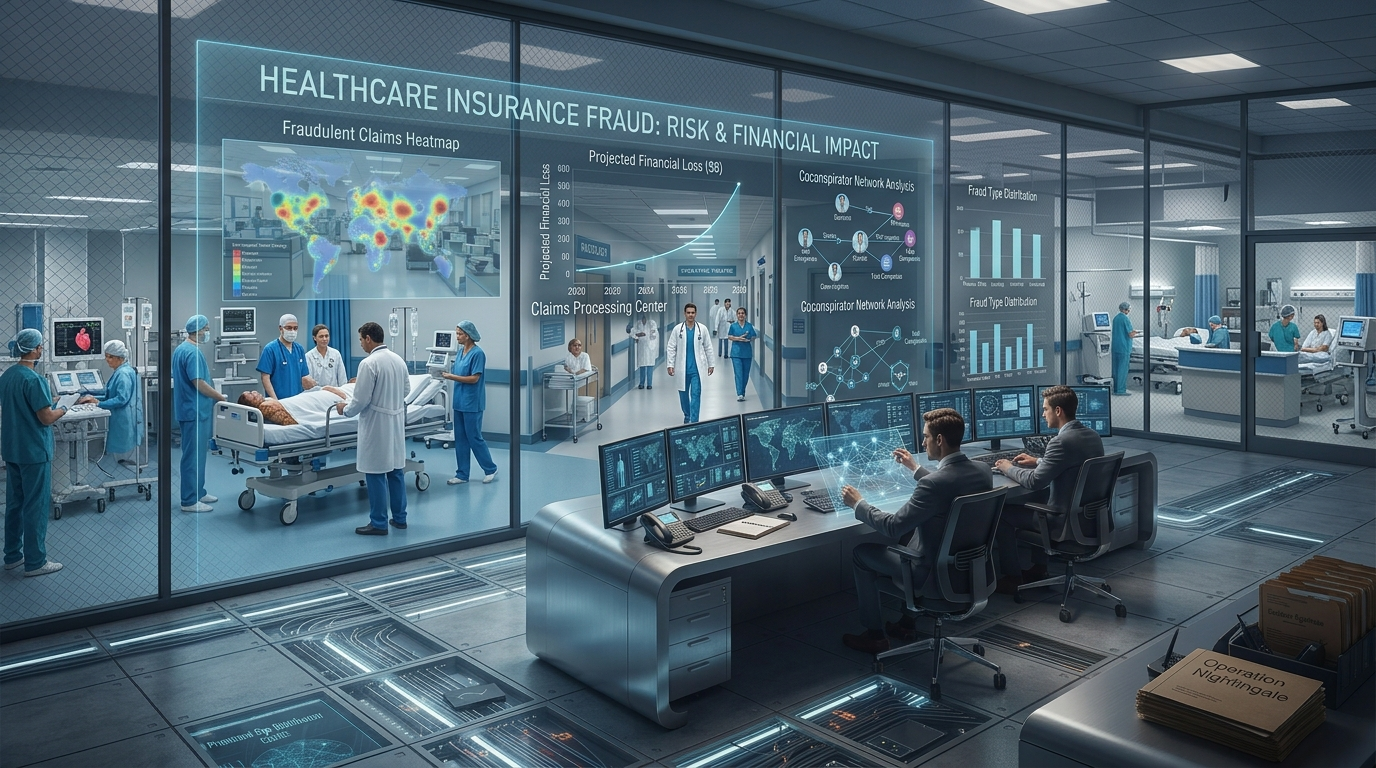

# Healthcare Insurance Fraud Analysis: Risk and Financial Impact

## Business Importance
Fraud, waste and abuse in healthcare claims directly increase the cost of coverage. Every fraudulent claim paid is money that raises premiums, reduces margins and weakens the insurer’s financial position. Fraud analytics helps an insurer decide which claims and providers deserve investigation, recover more money per review and protect honest policyholders and providers from unnecessary friction.

## Business Problem
An insurer receives far more claims than its special investigations unit (SIU) can review. Reviewing every claim is too slow and too expensive, while paying every claim without review lets fraud through. The challenge is to rank claims and providers by fraud risk so that limited investigation capacity is spent where the expected recovery is highest, while also separating providers who are truly high risk from those who only look risky because they have few claims.

## Project Objective
This project builds a data-driven framework to detect fraudulent claims at the moment of submission, estimate provider-level fraud risk, and quantify the financial impact of fraud. It then identifies the review strategy that maximizes expected savings under a fixed investigation capacity. The final output is a prioritized list of claims and providers to review, with the expected dollars recovered.

### Importing libraries and loading the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_excel(
    "healthcare_fraud_detection.xlsx",
    sheet_name="healthcare_fraud_detection",
    engine="openpyxl"
)

# Dates come as month/day/year
df["Claim_Submission_Date"] = pd.to_datetime(
    df["Claim_Submission_Date"], format="%m/%d/%Y"
)

df.head()

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m,Is_Fraud
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,Outpatient,1,2.0,0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,5,Inpatient,1,2.0,0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,5,Inpatient,1,3.0,0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,Emergency,0,5.0,0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,5,Inpatient,0,4.0,0


### Data Explanation

| Column | Description |
| :--- | :--- |
| `Provider_ID` | Identifier of the provider who submitted the claim. |
| `Claim_ID` | Unique identifier of the claim, used only as a key. |
| `Patient_Age` / `Patient_Gender` | Age and gender of the patient. |
| `Diagnosis_Code` | ICD-10 diagnosis code. |
| `Procedure_Code` | CPT procedure code. |
| `Claim_Amount` | Amount billed by the provider. |
| `Approved_Amount` | Amount approved by the insurer after review. |
| `Insurance_Type` | Type of coverage (Medicaid, Self-Pay, etc.). |
| `Claim_Submission_Date` | Date the claim was submitted. |
| `Days_Between_Service_and_Claim` | Days between the service and the claim submission. |
| `Number_of_Claims_Per_Provider_Monthly` | Monthly claim volume of the provider. |
| `Provider_Specialty` | Medical specialty of the provider. |
| `Patient_State` | State of the patient. |
| `Claim_Status` | Outcome of the claim (Approved, Pending, etc.). |
| `Length_of_Stay` | Days of hospital stay (0 for outpatient). |
| `Visit_Type` | Inpatient or Outpatient. |
| `Chronic_Condition_Flag` | 1 if the patient has a chronic condition. |
| `Prior_Visits_12m` | Patient visits in the previous 12 months. |
| `Is_Fraud` | Target: 1 = fraudulent claim, 0 = legitimate. |

### Dataset structure

In [2]:
print(df.shape)
df.info()

(10000, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   Provider_ID                            10000 non-null  object        
 1   Claim_ID                               10000 non-null  object        
 2   Patient_Age                            10000 non-null  int64         
 3   Patient_Gender                         10000 non-null  object        
 4   Diagnosis_Code                         10000 non-null  object        
 5   Procedure_Code                         10000 non-null  int64         
 6   Claim_Amount                           10000 non-null  float64       
 7   Approved_Amount                        10000 non-null  float64       
 8   Insurance_Type                         9650 non-null   object        
 9   Claim_Submission_Date                  10000 non-n

### Missing values and duplicates

In [3]:
missing = df.isnull().sum()
print(missing[missing > 0])

print("\nDuplicated Claim_ID:", df["Claim_ID"].duplicated().sum())
print("Unique providers   :", df["Provider_ID"].nunique())
print("Date range         :", df["Claim_Submission_Date"].min().date(),
      "to", df["Claim_Submission_Date"].max().date())

Insurance_Type        350
Provider_Specialty    350
Prior_Visits_12m      350
dtype: int64

Duplicated Claim_ID: 0
Unique providers   : 300
Date range         : 2021-01-06 to 2025-01-26


### Fraud prevalence

Is_Fraud
0    9171
1     829
Name: count, dtype: int64

Fraud rate: 8.29%


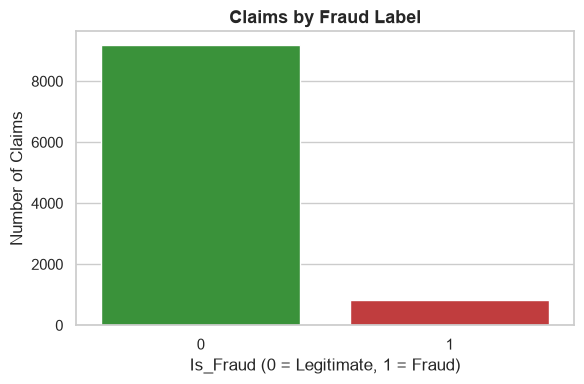

In [4]:
fraud_counts = df["Is_Fraud"].value_counts()
fraud_rate = df["Is_Fraud"].mean()

print(fraud_counts)
print(f"\nFraud rate: {fraud_rate:.2%}")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Is_Fraud", palette=["#2ca02c", "#d62728"])
plt.title("Claims by Fraud Label", fontsize=13, weight="bold")
plt.xlabel("Is_Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

**Conclusion:** This chart gives the share of claims labeled as fraud, which is the most important number for the rest of the project. If fraud is rare (for example below 5%), accuracy will be a misleading metric and we will need precision, recall and precision-recall AUC instead. A rare target also means we should be careful with how we split the data and handle the imbalance.

### Leakage check

Is_Fraud          0      1
Claim_Status              
Approved      0.978  0.022
Pending       0.773  0.227
Rejected      0.769  0.231


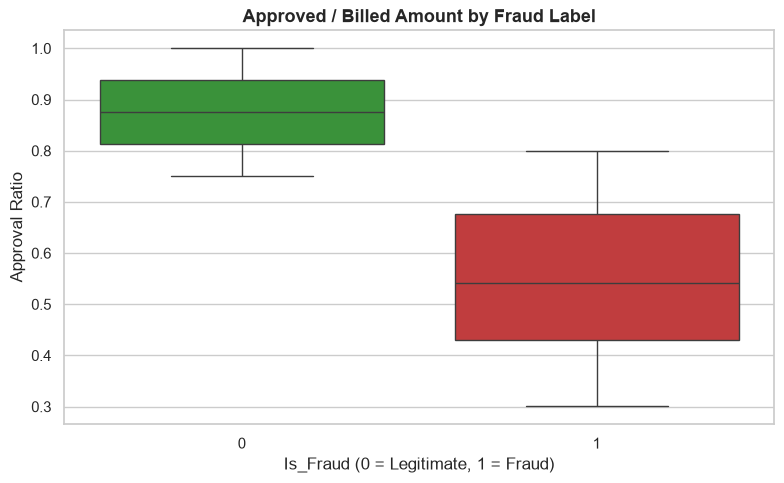

In [5]:
# Claim status vs fraud
print(pd.crosstab(df["Claim_Status"], df["Is_Fraud"], normalize="index").round(3))

# Approved amount relative to billed amount
df["Approval_Ratio"] = df["Approved_Amount"] / df["Claim_Amount"]

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Is_Fraud", y="Approval_Ratio",
            palette=["#2ca02c", "#d62728"])
plt.title("Approved / Billed Amount by Fraud Label", fontsize=13, weight="bold")
plt.xlabel("Is_Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Approval Ratio")
plt.tight_layout()
plt.show()

**Conclusion:** The table and boxplot test whether the post-review fields behave differently for fraudulent claims. If the fraud rate changes a lot across claim statuses, or the approval ratio separates the two groups, those fields carry information that exists only after the review. Using them would make the model look excellent in testing but useless in practice, so we exclude them from the features.

### Defining the feature set

In [6]:
# Columns that are only known after the claim is reviewed
leakage_cols = ["Approved_Amount", "Claim_Status", "Approval_Ratio"]

# Columns that are identifiers, not predictors
id_cols = ["Claim_ID", "Provider_ID"]

target = "Is_Fraud"

feature_cols = [c for c in df.columns
                if c not in leakage_cols + id_cols + [target]]

print("Features used at submission:")
for c in feature_cols:
    print(" -", c)

Features used at submission:
 - Patient_Age
 - Patient_Gender
 - Diagnosis_Code
 - Procedure_Code
 - Claim_Amount
 - Insurance_Type
 - Claim_Submission_Date
 - Days_Between_Service_and_Claim
 - Number_of_Claims_Per_Provider_Monthly
 - Provider_Specialty
 - Patient_State
 - Length_of_Stay
 - Visit_Type
 - Chronic_Condition_Flag
 - Prior_Visits_12m


**What this shows:** This list is the contract for the whole project: only information available when the claim arrives can be used to predict fraud. Provider_ID is kept out of the claim-level features but stays in the dataset, because we will use it later to build provider-level risk. Defining this once also keeps the later modeling steps consistent.

### Time-based split

Cutoff date : 2024-03-25
Train size  : 8,001  | fraud rate: 8.46%
Test size   : 1,999  | fraud rate: 7.60%


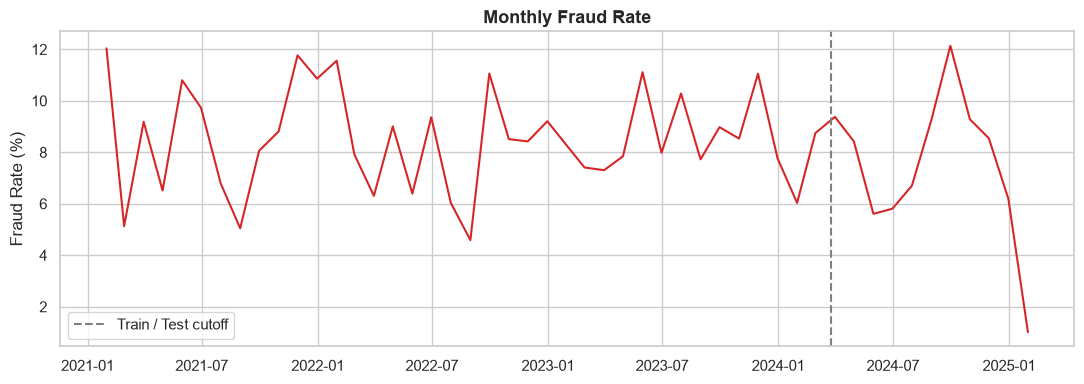

In [7]:
df = df.sort_values("Claim_Submission_Date").reset_index(drop=True)

cutoff = df["Claim_Submission_Date"].quantile(0.80)

train = df[df["Claim_Submission_Date"] <= cutoff].copy()
test  = df[df["Claim_Submission_Date"] >  cutoff].copy()

print(f"Cutoff date : {cutoff.date()}")
print(f"Train size  : {len(train):,}  | fraud rate: {train[target].mean():.2%}")
print(f"Test size   : {len(test):,}  | fraud rate: {test[target].mean():.2%}")

# Fraud rate over time
monthly = (df.set_index("Claim_Submission_Date")[target]
             .resample("M").mean())

plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly.values * 100, color="#d62728")
plt.axvline(cutoff, color="gray", linestyle="--", label="Train / Test cutoff")
plt.title("Monthly Fraud Rate", fontsize=13, weight="bold")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The split keeps all training claims before the cutoff and all test claims after it, so the model is evaluated on the future instead of on randomly mixed rows. The fraud rate in both sets should be similar; a large gap would signal that fraud behavior changed over time. The monthly line also shows whether the data has a trend or seasonality that we should keep in mind during modeling.

### Fraud rate by category

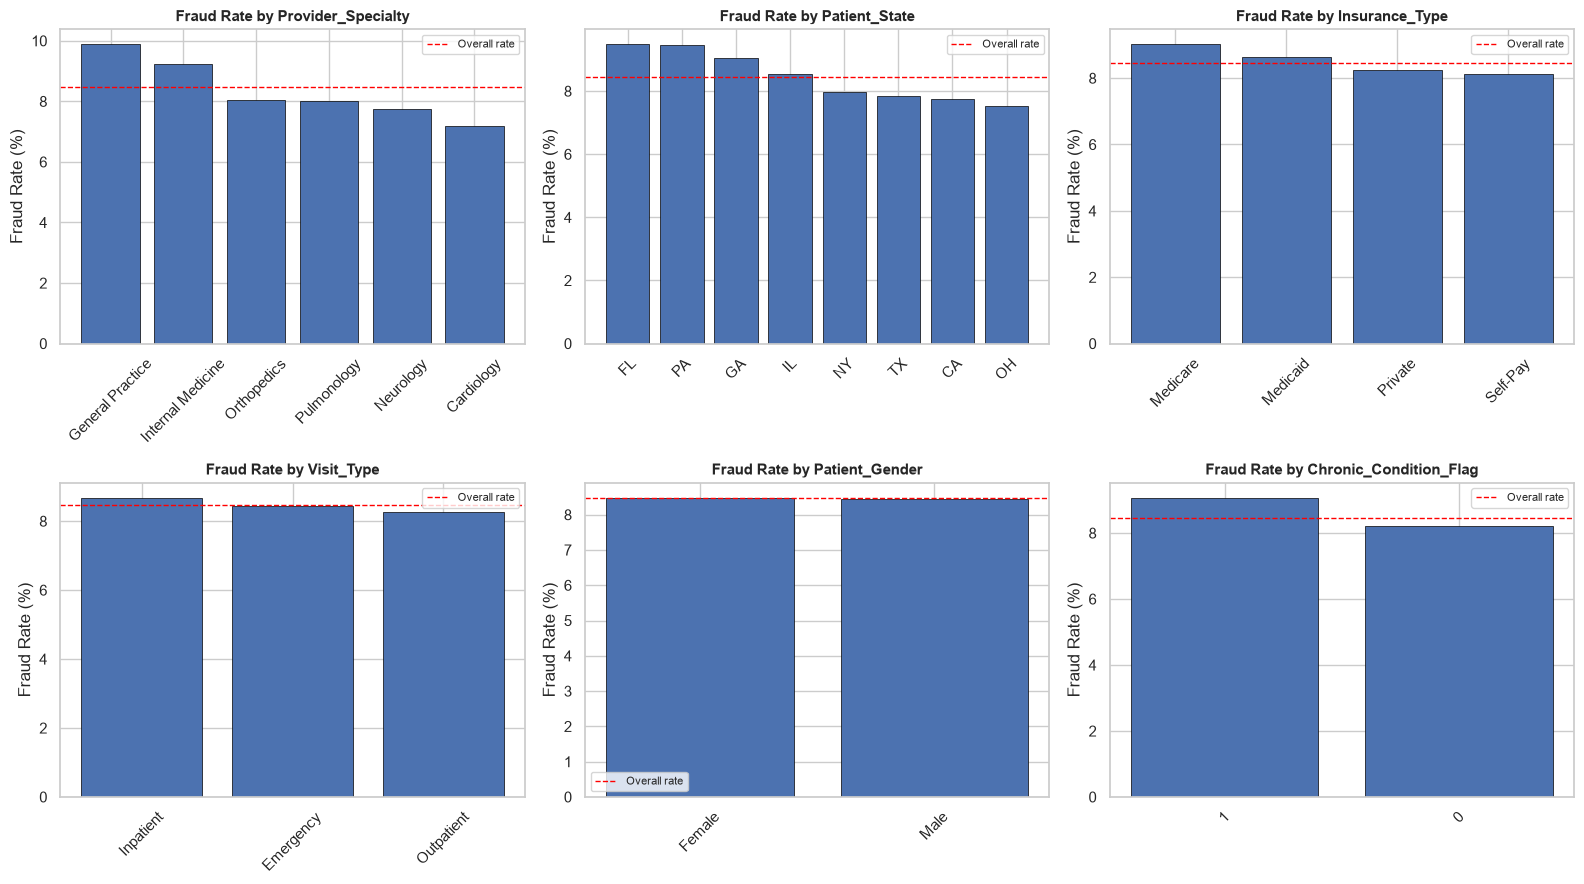

In [8]:
cat_cols = ["Provider_Specialty", "Patient_State", "Insurance_Type",
            "Visit_Type", "Patient_Gender", "Chronic_Condition_Flag"]

overall_rate = train["Is_Fraud"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    rate = (train.groupby(col)["Is_Fraud"].mean() * 100).sort_values(ascending=False)
    ax.bar(rate.index.astype(str), rate.values, color="#4C72B0", edgecolor="black", linewidth=0.5)
    ax.axhline(overall_rate, color="red", linestyle="--", linewidth=1, label="Overall rate")
    ax.set_title(f"Fraud Rate by {col}", fontsize=11, weight="bold")
    ax.set_ylabel("Fraud Rate (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**Conclusion:** Each chart compares the fraud rate of every category with the overall rate (red line). Categories far above the line are candidates for higher risk, while categories near it carry little signal. These are only visual differences, so the next step checks which ones are statistically real.

### Chi-square tests of independence

In [9]:
from scipy import stats

results = []
for col in cat_cols:
    table = pd.crosstab(train[col], train["Is_Fraud"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    results.append({"Variable": col, "Chi2": chi2, "p_value": p})

chi_df = pd.DataFrame(results).sort_values("p_value")

# Bonferroni: we run several tests, so the threshold is stricter
alpha = 0.05 / len(cat_cols)
chi_df["Significant"] = chi_df["p_value"] < alpha

print(f"Bonferroni threshold: {alpha:.4f}")
chi_df

Bonferroni threshold: 0.0083


,Variable,Chi2,p_value,Significant
0,Provider_Specialty,8.829944,0.116042,False
5,Chronic_Condition_Flag,1.469026,0.225499,False
1,Patient_State,5.673862,0.578304,False
2,Insurance_Type,1.208711,0.750916,False
3,Visit_Type,0.272292,0.872715,False
4,Patient_Gender,0.000248,0.987426,False


**Conclusion:** The chi-square test asks whether the fraud rate depends on a variable or whether the differences could be random. Because we run six tests at once, the Bonferroni threshold is stricter than 0.05, which reduces false discoveries. Variables marked as significant are the categorical signals worth keeping for the model.

### Numeric variables by fraud label

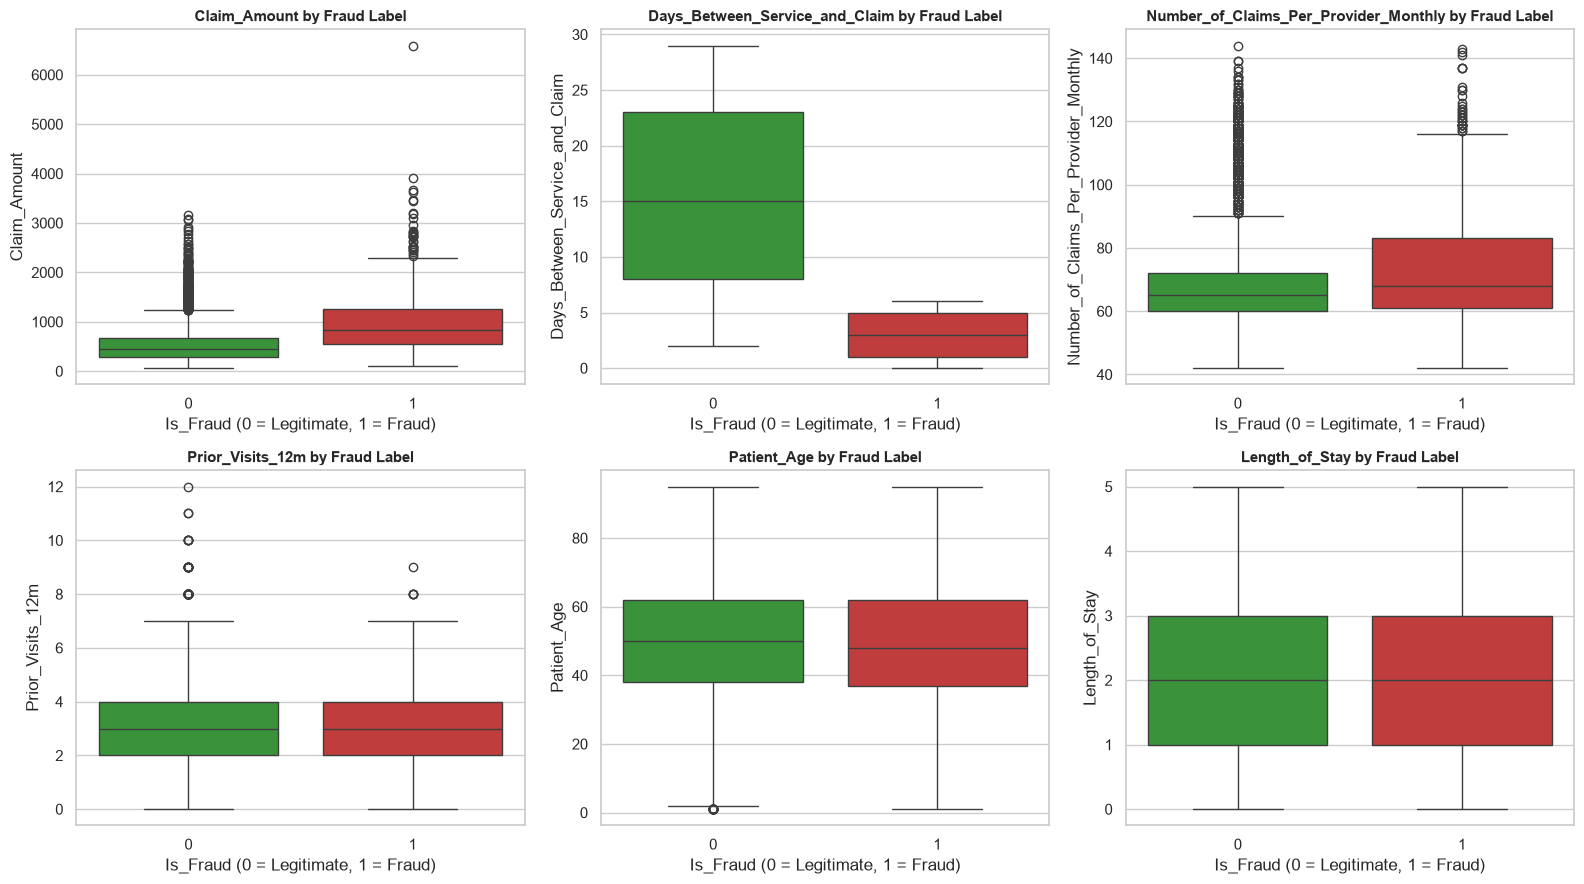

In [10]:
num_cols = ["Claim_Amount", "Days_Between_Service_and_Claim",
            "Number_of_Claims_Per_Provider_Monthly", "Prior_Visits_12m",
            "Patient_Age", "Length_of_Stay"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=train, x="Is_Fraud", y=col, ax=ax,
                palette=["#2ca02c", "#d62728"])
    ax.set_title(f"{col} by Fraud Label", fontsize=11, weight="bold")
    ax.set_xlabel("Is_Fraud (0 = Legitimate, 1 = Fraud)")

plt.tight_layout()
plt.show()

**Conclusion:** The boxplots compare the typical value and spread of each numeric variable for legitimate and fraudulent claims. A variable is useful when the two boxes are clearly shifted, for example if fraudulent claims have higher amounts or come from busier providers. Overlapping boxes suggest the variable alone does not separate fraud well.

### Mann-Whitney tests for numeric variables

In [11]:
rows = []
for col in num_cols:
    legit = train.loc[train["Is_Fraud"] == 0, col].dropna()
    fraud = train.loc[train["Is_Fraud"] == 1, col].dropna()
    stat, p = stats.mannwhitneyu(legit, fraud, alternative="two-sided")
    rows.append({
        "Variable": col,
        "Median_Legit": legit.median(),
        "Median_Fraud": fraud.median(),
        "p_value": p
    })

mw_df = pd.DataFrame(rows).sort_values("p_value")
mw_df["Significant"] = mw_df["p_value"] < 0.05 / len(num_cols)
mw_df.round(4)

,Variable,Median_Legit,Median_Fraud,p_value,Significant
1,Days_Between_Service_and_Claim,15.00,3.0,0.0000,True
0,Claim_Amount,443.59,823.9,0.0000,True
2,Number_of_Claims_Per_Provider_Monthly,65.00,68.0,0.0000,True
5,Length_of_Stay,2.00,2.0,0.1130,False
4,Patient_Age,50.00,48.0,0.1338,False
3,Prior_Visits_12m,3.00,3.0,0.5322,False


**Conclusion:** The Mann-Whitney test compares the two groups without assuming a normal distribution, which suits skewed variables like claim amounts. We read it together with the medians: a tiny p-value with nearly equal medians means a statistically real but practically small difference. The variables with both a clear median gap and a low p-value are the strongest numeric signals.

### Billed amount distribution

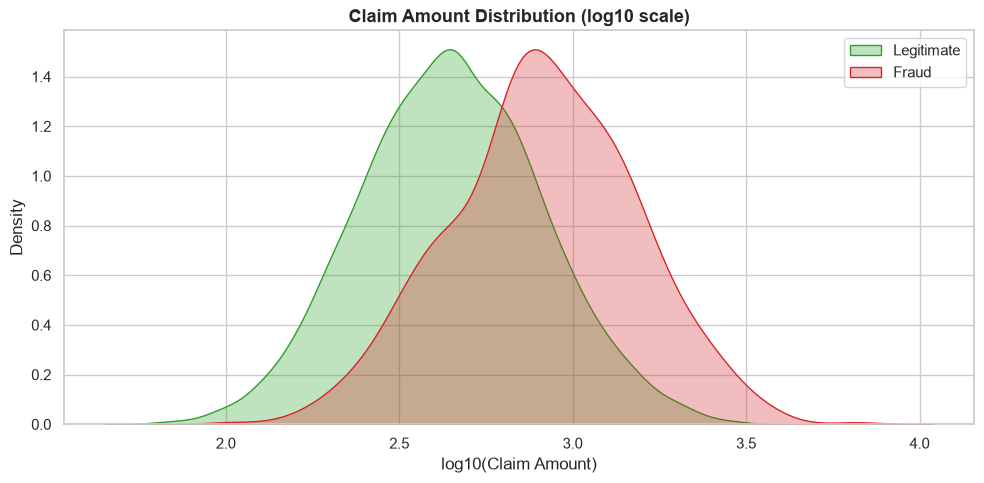

In [12]:
plt.figure(figsize=(10, 5))
sns.kdeplot(np.log10(train.loc[train["Is_Fraud"] == 0, "Claim_Amount"]),
            label="Legitimate", color="#2ca02c", fill=True, alpha=0.3)
sns.kdeplot(np.log10(train.loc[train["Is_Fraud"] == 1, "Claim_Amount"]),
            label="Fraud", color="#d62728", fill=True, alpha=0.3)
plt.title("Claim Amount Distribution (log10 scale)", fontsize=13, weight="bold")
plt.xlabel("log10(Claim Amount)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** Claim amounts are highly skewed, so the log scale makes the two groups easier to compare. If the fraud curve sits to the right or has a different shape, fraudulent claims tend to be billed differently. This also tells us whether a log transformation of the amount will help the models later.

### Benford’s law on claim amounts

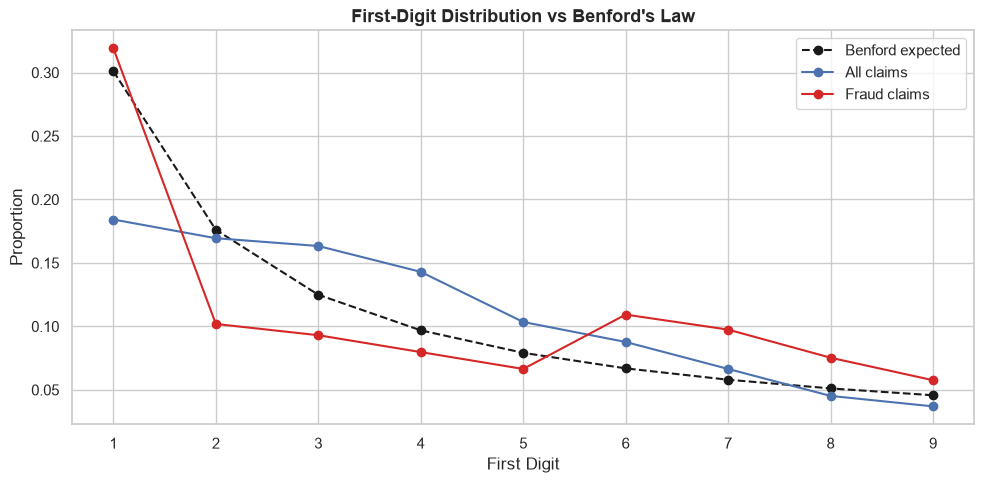

All claims -> Chi2: 774.57 | p-value: 0.0000


In [13]:
def first_digit(x):
    return int(str(abs(x)).replace(".", "").lstrip("0")[0])

train["First_Digit"] = train["Claim_Amount"].apply(first_digit)

digits = np.arange(1, 10)
benford = np.log10(1 + 1 / digits)

obs_all   = train["First_Digit"].value_counts(normalize=True).reindex(digits, fill_value=0)
obs_fraud = (train.loc[train["Is_Fraud"] == 1, "First_Digit"]
                  .value_counts(normalize=True).reindex(digits, fill_value=0))

plt.figure(figsize=(10, 5))
plt.plot(digits, benford, "k--o", label="Benford expected")
plt.plot(digits, obs_all.values, "-o", color="#4C72B0", label="All claims")
plt.plot(digits, obs_fraud.values, "-o", color="#d62728", label="Fraud claims")
plt.title("First-Digit Distribution vs Benford's Law", fontsize=13, weight="bold")
plt.xlabel("First Digit")
plt.ylabel("Proportion")
plt.legend()
plt.tight_layout()
plt.show()

# Goodness-of-fit test against Benford
n_all = len(train)
chi2, p = stats.chisquare(obs_all.values * n_all, benford * n_all)
print(f"All claims -> Chi2: {chi2:.2f} | p-value: {p:.4f}")

**Conclusion:** This chart demonstrates that the claim data significantly deviates from the natural distribution predicted by Benford's Law, serving as a strong indicator of manipulation. The "Fraud claims" line (red) exhibits a highly erratic pattern with a massive unnatural spike at digit 1 and irregular peaks at digits 6 and 7, suggesting that fraudsters are not choosing amounts randomly but are likely targeting specific monetary thresholds (such as keeping claims just under a $2,000 limit). The statistical test confirms this with a p-value of 0.0000, proving that the data is not naturally occurring and validating Benford's Law as a powerful forensic tool to detect the distinct "fingerprint" of fraudulent behavior.

### Visit type and length of stay consistency

In [14]:
# Outpatient visits should not have a hospital stay; inpatient visits should
train["Stay_Inconsistent"] = (
    ((train["Visit_Type"] == "Outpatient") & (train["Length_of_Stay"] > 0)) |
    ((train["Visit_Type"] == "Inpatient")  & (train["Length_of_Stay"] == 0))
).astype(int)

print("Inconsistent claims:", train["Stay_Inconsistent"].sum(),
      f"({train['Stay_Inconsistent'].mean():.2%})")

print(train.groupby("Stay_Inconsistent")["Is_Fraud"].agg(["mean", "count"]).round(4))

Inconsistent claims: 2715 (33.93%)
                     mean  count
Stay_Inconsistent               
0                  0.0861   5286
1                  0.0818   2715


**Conclusion:** This flag marks claims where the visit type and the length of stay contradict each other, such as an outpatient visit with several hospital days. If the fraud rate is higher in the flagged group, the flag is a simple and explainable rule we can add as a feature. If both groups have the same fraud rate, the inconsistency is just noise in the data.

### Rare diagnosis and procedure combinations

In [15]:
train["Dx_Proc_Pair"] = train["Diagnosis_Code"] + "_" + train["Procedure_Code"].astype(str)

pair_counts = train["Dx_Proc_Pair"].value_counts()
train["Pair_Frequency"] = train["Dx_Proc_Pair"].map(pair_counts)

# Rare = bottom 10% of pair frequency
threshold = train["Pair_Frequency"].quantile(0.10)
train["Rare_Pair"] = (train["Pair_Frequency"] <= threshold).astype(int)

print("Distinct pairs:", len(pair_counts))
print("Share of claims flagged as rare pair:", f"{train['Rare_Pair'].mean():.2%}")
print(train.groupby("Rare_Pair")["Is_Fraud"].agg(["mean", "count"]).round(4))

Distinct pairs: 90
Share of claims flagged as rare pair: 11.75%
             mean  count
Rare_Pair               
0          0.0837   7061
1          0.0915    940


**Conclusion:** A diagnosis billed with an unusual procedure can point to services that do not match the patient’s condition. This table checks whether claims with rare diagnosis-procedure pairs have a different fraud rate from common ones. If they do, pair frequency becomes a useful engineered feature for the model.

### Correlation with the fraud label

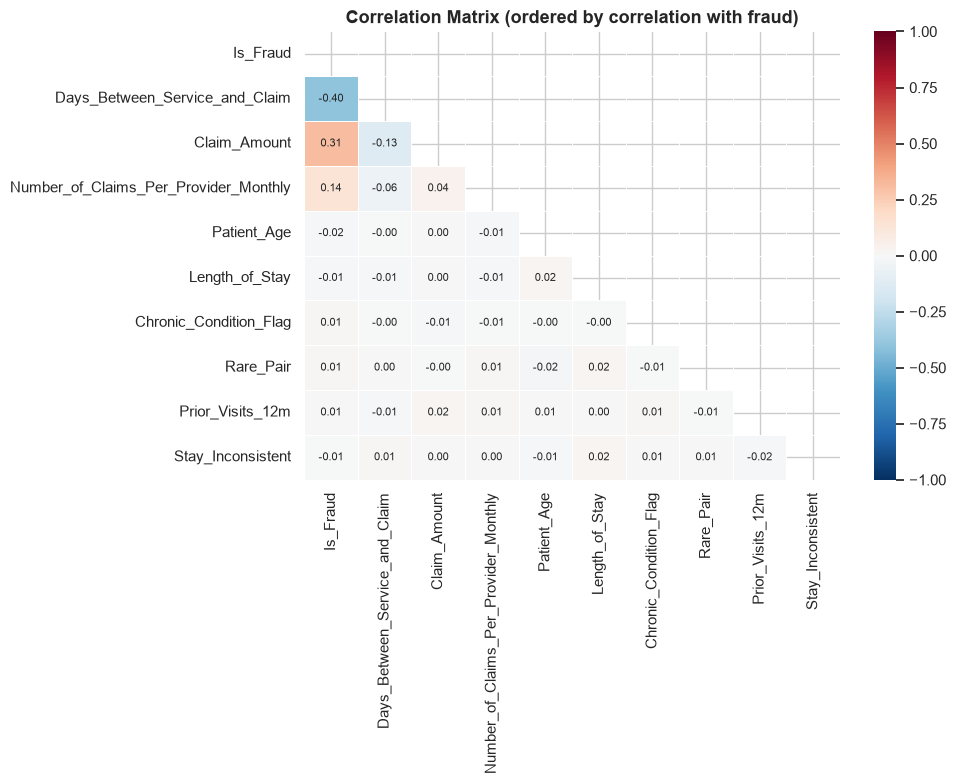

In [16]:
threshold = train["Pair_Frequency"].quantile(0.10)
train["Rare_Pair"] = (train["Pair_Frequency"] <= threshold).astype(int)

corr_cols = num_cols + ["Chronic_Condition_Flag", "Stay_Inconsistent",
                        "Rare_Pair", "Is_Fraud"]
corr = train[corr_cols].corr()

order = corr["Is_Fraud"].abs().sort_values(ascending=False).index
corr = corr.loc[order, order]

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5)
plt.title("Correlation Matrix (ordered by correlation with fraud)", fontsize=13, weight="bold")
plt.tight_layout()
plt.show()

**Conclusion:** The heatmap ranks the numeric and engineered variables by how strongly they move with the fraud label, and also shows overlap between predictors. Correlations with fraud are usually small in this kind of data, so even values around 0.05 to 0.15 can matter. Predictors that are highly correlated with each other carry repeated information, which is useful to know before fitting the logistic model.

### Provider-level table

Count of Providers: 256
**************************************************
Claims stats:
count    256.0
mean      27.1
std        5.1
min       15.0
25%       24.0
50%       27.0
75%       30.0
max       44.0
Name: Claims, dtype: float64
**************************************************
Top 10 Providers by Fraud Amount:
    Provider_ID  Claims  Fraud_Claims  Fraud_Amount  Raw_Rate
110       P0110      35            13      15428.11  0.371429
101       P0101      29             7      13903.57  0.241379
86        P0086      31            14      12790.51  0.451613
223       P0223      35            10      11400.91  0.285714
293       P0293      27             9       8042.93  0.333333
27        P0027      32             9       7980.99  0.281250
289       P0289      22             5       7931.84  0.227273
214       P0214      30             5       7732.15  0.166667
259       P0259      31             7       7228.82  0.225806
58        P0058      28             9       7162.03  0.32

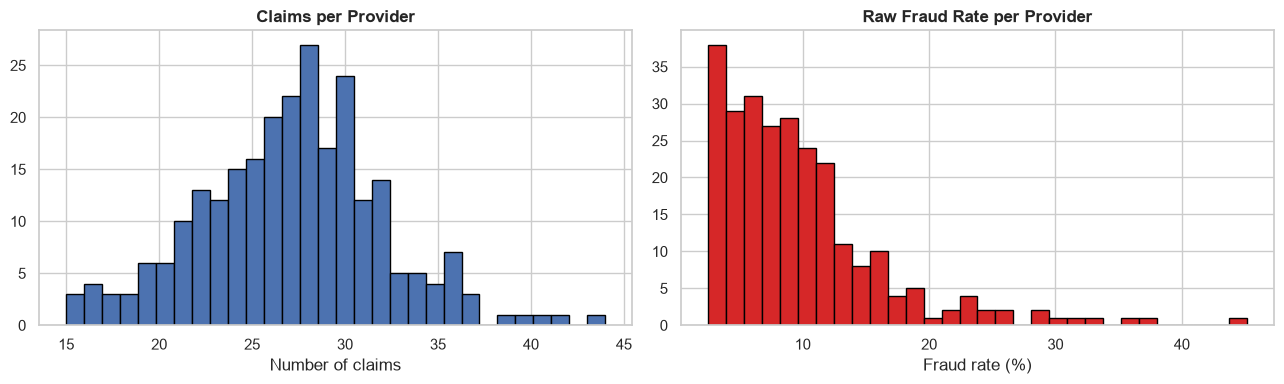

In [46]:
# Dollar amount of fraud per claim
train["Fraud_Amount"] = train["Claim_Amount"] * train["Is_Fraud"]

prov = train.groupby("Provider_ID").agg(
    Claims=("Claim_ID", "count"),
    Fraud_Claims=("Is_Fraud", "sum"),
    Fraud_Amount=("Fraud_Amount", "sum")
).reset_index().query(
    "Fraud_Amount > 0"
).sort_values(
    by="Fraud_Amount", ascending=False
)

prov["Raw_Rate"] = prov["Fraud_Claims"] / prov["Claims"]

print("Count of Providers:", len(prov))
print("*"*50)
print("Claims stats:")
print(prov["Claims"].describe().round(1))
print("*"*50)
print("Top 10 Providers by Fraud Amount:")
print(prov.head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(prov["Claims"], bins=30, color="#4C72B0", edgecolor="black")
axes[0].set_title("Claims per Provider", weight="bold")
axes[0].set_xlabel("Number of claims")
axes[1].hist(prov["Raw_Rate"] * 100, bins=30, color="#d62728", edgecolor="black")
axes[1].set_title("Raw Fraud Rate per Provider", weight="bold")
axes[1].set_xlabel("Fraud rate (%)")
plt.tight_layout()
plt.show()

**Conclustion:** Each row is one provider, with its number of claims, fraud claims and billed fraud dollars. The left chart tells us how much data each provider has, and the right chart shows how spread out the raw fraud rates are. Providers with few claims will produce extreme rates (0% or very high) purely by chance, which is the problem the next step solves.

### Credibility estimate (Bühlmann-Straub)

In [18]:
p_bar = prov["Fraud_Claims"].sum() / prov["Claims"].sum()   # portfolio fraud rate
n_i   = prov["Claims"]
m     = len(prov)
n_tot = n_i.sum()

# Variance within providers (pure chance) and between providers (real differences)
epv = p_bar * (1 - p_bar)
ss  = (n_i * (prov["Raw_Rate"] - p_bar) ** 2).sum()
vhm = (ss - (m - 1) * epv) / (n_tot - (n_i ** 2).sum() / n_tot)

if vhm <= 0:
    print("Between-provider variance is not above chance: providers look alike.")
    vhm = 1e-9

k = epv / vhm                       # claims needed for 50% credibility
prov["Z"] = n_i / (n_i + k)         # credibility weight
prov["Cred_Rate"] = prov["Z"] * prov["Raw_Rate"] + (1 - prov["Z"]) * p_bar

print(f"Portfolio fraud rate     : {p_bar:.2%}")
print(f"Within variance (EPV)    : {epv:.5f}")
print(f"Between variance (VHM)   : {vhm:.6f}")
print(f"Credibility constant k   : {k:,.0f} claims")
print(f"Average credibility Z    : {prov['Z'].mean():.2f}")

Portfolio fraud rate     : 8.46%
Within variance (EPV)    : 0.07745
Between variance (VHM)   : 0.002134
Credibility constant k   : 36 claims
Average credibility Z    : 0.42


**Conclusion:** The portfolio exhibits an overall fraud rate of 8.46%, with a within-provider variance (EPV) of 0.07745 indicating substantial variation in individual claim outcomes. The between-provider variance (VHM) of 0.002134 suggests relatively limited differences in underlying fraud risk across providers. The credibility constant of 36 claims and average credibility factor of 0.42 indicate that provider-level experience receives 42% weight, while the remaining 58% relies on the overall portfolio fraud rate.

### Raw rate vs credibility rate

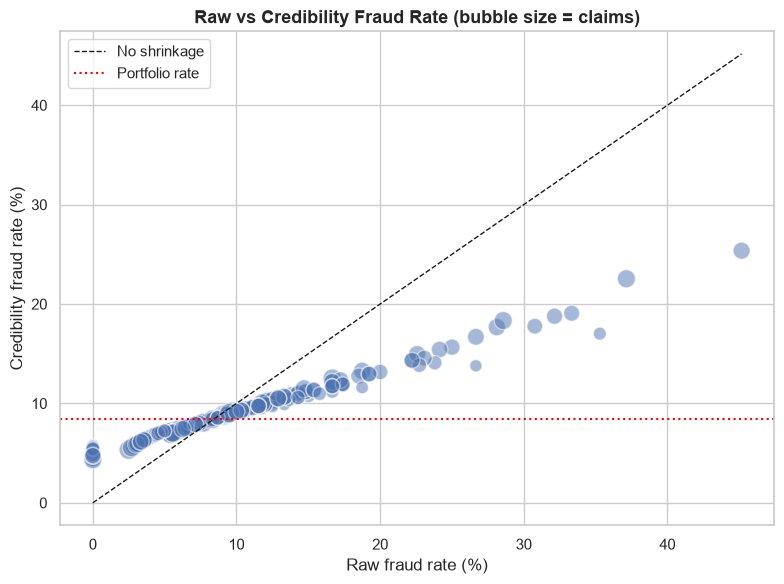

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(prov["Raw_Rate"] * 100, prov["Cred_Rate"] * 100,
            s=prov["Claims"] / prov["Claims"].max() * 200 + 10,
            alpha=0.5, color="#4C72B0", edgecolor="white")
lim = prov["Raw_Rate"].max() * 100
plt.plot([0, lim], [0, lim], "k--", linewidth=1, label="No shrinkage")
plt.axhline(p_bar * 100, color="red", linestyle=":", label="Portfolio rate")
plt.title("Raw vs Credibility Fraud Rate (bubble size = claims)", fontsize=13, weight="bold")
plt.xlabel("Raw fraud rate (%)")
plt.ylabel("Credibility fraud rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** Points on the dashed line were not changed, while points pulled toward the red line were shrunk toward the portfolio average. Small providers (small bubbles) move the most, and large providers stay close to their raw rate. The result is a fairer risk estimate that is less likely to flag a provider just because of a few unlucky claims.

### Funnel plot: who is truly above chance?

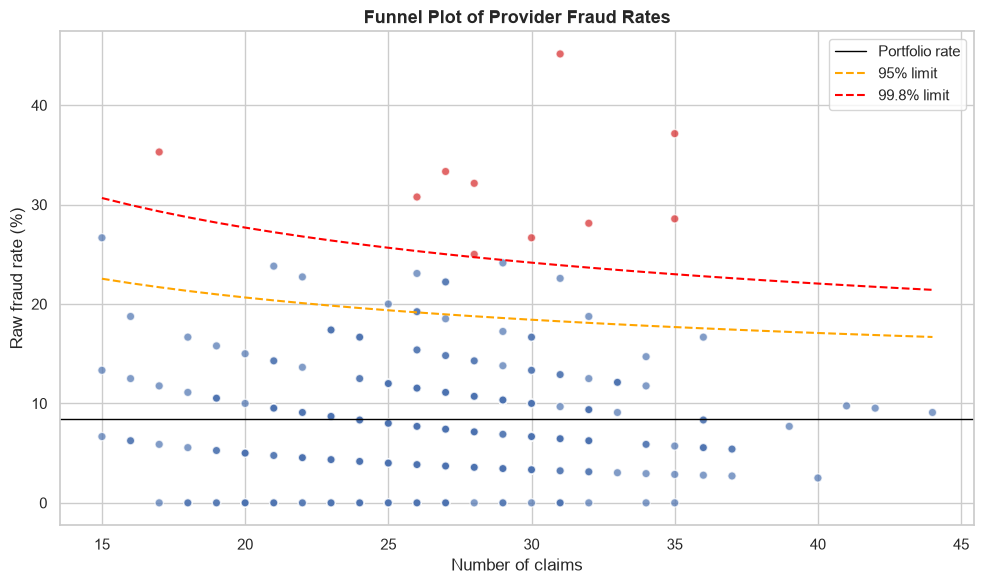

Providers above the 99.8% limit: 10 of 300


In [20]:
n_range = np.arange(prov["Claims"].min(), prov["Claims"].max() + 1)
se = np.sqrt(p_bar * (1 - p_bar) / n_range)
upper_95 = (p_bar + 1.96 * se) * 100
upper_99 = (p_bar + 3.09 * se) * 100   # 99.8% limit

# Flag providers above the 99.8% limit
se_i = np.sqrt(p_bar * (1 - p_bar) / prov["Claims"])
prov["Above_Limit"] = prov["Raw_Rate"] > p_bar + 3.09 * se_i

plt.figure(figsize=(10, 6))
plt.scatter(prov["Claims"], prov["Raw_Rate"] * 100,
            c=prov["Above_Limit"].map({True: "#d62728", False: "#4C72B0"}),
            alpha=0.7, edgecolor="white")
plt.axhline(p_bar * 100, color="black", linewidth=1, label="Portfolio rate")
plt.plot(n_range, upper_95, "--", color="orange", label="95% limit")
plt.plot(n_range, upper_99, "--", color="red", label="99.8% limit")
plt.title("Funnel Plot of Provider Fraud Rates", fontsize=13, weight="bold")
plt.xlabel("Number of claims")
plt.ylabel("Raw fraud rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

print("Providers above the 99.8% limit:", prov["Above_Limit"].sum(), "of", len(prov))

**Conclusion:** The funnel plot shows that 10 out of 300 providers exceed the 99.8% upper control limit, indicating fraud rates significantly higher than expected under random variation alone. The funnel narrows as claim volume increases, reflecting greater statistical reliability and lower expected random fluctuations for providers with larger claim samples. These 10 providers represent the strongest candidates for further fraud investigation, although exceeding the statistical threshold does not independently prove fraudulent activity.

### Provider watchlist

In [21]:
watchlist = (prov.sort_values("Cred_Rate", ascending=False)
                 .head(10)[["Provider_ID", "Claims", "Fraud_Claims",
                            "Raw_Rate", "Cred_Rate", "Z", "Fraud_Amount"]])

watchlist["Raw_Rate"]  = (watchlist["Raw_Rate"] * 100).round(1)
watchlist["Cred_Rate"] = (watchlist["Cred_Rate"] * 100).round(1)
watchlist["Z"] = watchlist["Z"].round(2)
watchlist["Fraud_Amount"] = watchlist["Fraud_Amount"].round(0)
watchlist

,Provider_ID,Claims,Fraud_Claims,Raw_Rate,Cred_Rate,Z,Fraud_Amount
86,P0086,31,14,45.2,25.4,0.46,12791.0
110,P0110,35,13,37.1,22.5,0.49,15428.0
293,P0293,27,9,33.3,19.1,0.43,8043.0
58,P0058,28,9,32.1,18.8,0.44,7162.0
223,P0223,35,10,28.6,18.3,0.49,11401.0
104,P0104,26,8,30.8,17.8,0.42,6454.0
27,P0027,32,9,28.1,17.7,0.47,7981.0
159,P0159,17,6,35.3,17.0,0.32,3906.0
166,P0166,30,8,26.7,16.7,0.45,6332.0
71,P0071,28,7,25.0,15.7,0.44,6215.0


**Conclusion:** This is the top 10 providers ranked by credibility rate, which is the ranking an investigator should trust more than the raw one. Comparing the raw and credibility columns shows who stays on the list after adjusting for sample size. The fraud amount column adds the financial weight, so the list reflects both risk and dollars.

### Concentration of fraud losses

Top 10% of providers account for 32.1% of the fraud dollars


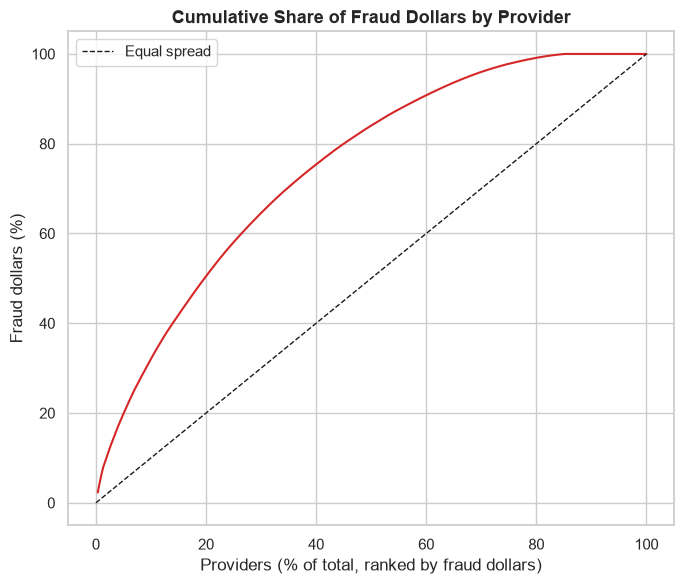

In [22]:
conc = prov.sort_values("Fraud_Amount", ascending=False).reset_index(drop=True)
conc["Cum_Share_Loss"] = conc["Fraud_Amount"].cumsum() / conc["Fraud_Amount"].sum()
conc["Cum_Share_Providers"] = (conc.index + 1) / len(conc)

top10 = conc.loc[conc["Cum_Share_Providers"] <= 0.10, "Cum_Share_Loss"].iloc[-1]
print(f"Top 10% of providers account for {top10:.1%} of the fraud dollars")

plt.figure(figsize=(7, 6))
plt.plot(conc["Cum_Share_Providers"] * 100, conc["Cum_Share_Loss"] * 100, color="#d62728")
plt.plot([0, 100], [0, 100], "k--", linewidth=1, label="Equal spread")
plt.title("Cumulative Share of Fraud Dollars by Provider", fontsize=13, weight="bold")
plt.xlabel("Providers (% of total, ranked by fraud dollars)")
plt.ylabel("Fraud dollars (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The cumulative distribution curve indicates that the top 10% of providers account for 32.1% of total fraud dollars, demonstrating a notable concentration of financial losses among a relatively small group. The curve's deviation above the equal-distribution line confirms that fraud losses are unevenly distributed across providers. This suggests that prioritizing high-loss providers for targeted audits and investigations could improve recovery efficiency and maximize the impact of fraud prevention efforts.

### Frequency: fraud claims per month

Months used          : 37
Mean fraud claims    : 17.5
Variance             : 18.0
Dispersion (var/mean): 1.02


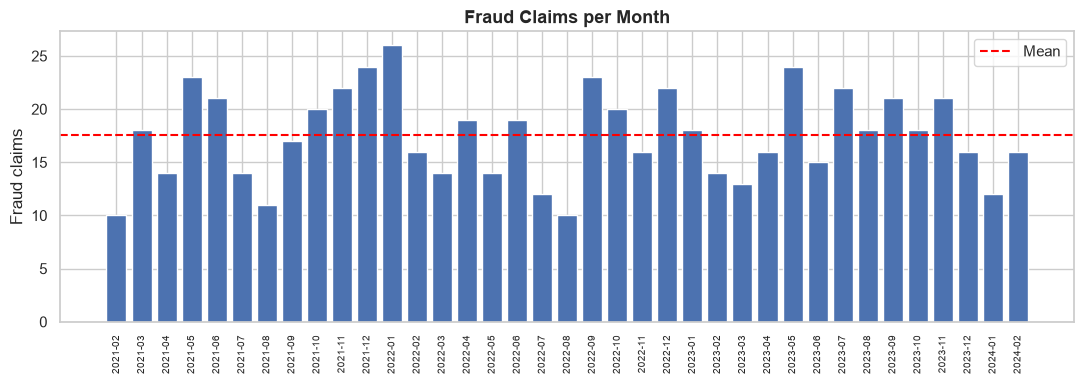

In [23]:
train["Month"] = train["Claim_Submission_Date"].dt.to_period("M")

monthly = train.groupby("Month")["Is_Fraud"].sum()
monthly = monthly.iloc[1:-1]   # drop first and last month, they may be partial

mean_m = monthly.mean()
var_m  = monthly.var()

print(f"Months used          : {len(monthly)}")
print(f"Mean fraud claims    : {mean_m:.1f}")
print(f"Variance             : {var_m:.1f}")
print(f"Dispersion (var/mean): {var_m / mean_m:.2f}")

plt.figure(figsize=(11, 4))
plt.bar(monthly.index.astype(str), monthly.values, color="#4C72B0")
plt.axhline(mean_m, color="red", linestyle="--", label="Mean")
plt.title("Fraud Claims per Month", fontsize=13, weight="bold")
plt.ylabel("Fraud claims")
plt.xticks(rotation=90, fontsize=7)
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** Across the 37 months analyzed, providers averaged 17.5 fraud claims per month, with a variance of 18.0. The dispersion ratio of 1.02 indicates that the variance is nearly equal to the mean, suggesting that a Poisson distribution is appropriate for modeling the monthly fraud claim frequency. This indicates relatively stable claim frequency without meaningful overdispersion or underdispersion.

### Severity: size of fraudulent claims

Fraud claims analysed : 677
Mean / Median amount  : $989 / $824
AIC Lognormal         : 10,358
AIC Gamma             : 10,386
Best severity model   : Lognormal


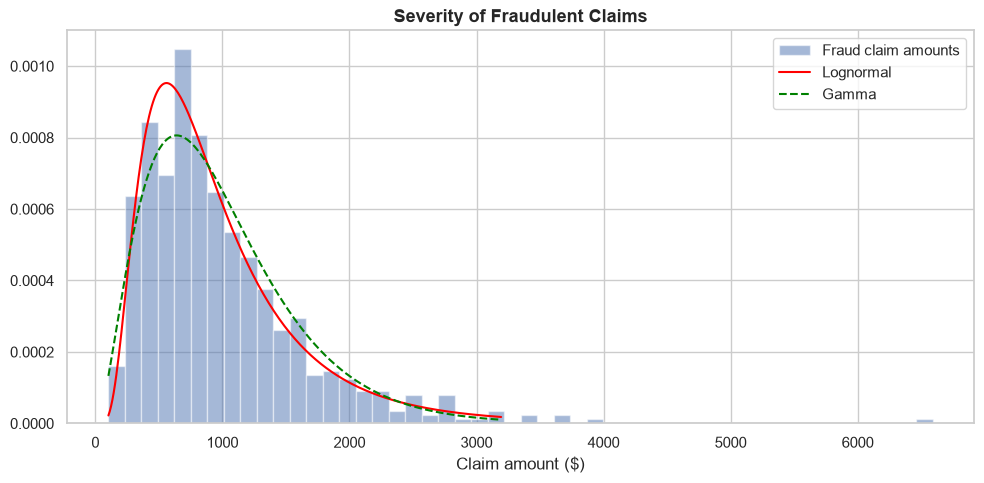

In [24]:
sev = train.loc[train["Is_Fraud"] == 1, "Claim_Amount"]

ln_params = stats.lognorm.fit(sev, floc=0)
gm_params = stats.gamma.fit(sev, floc=0)

# AIC (2 free parameters each, location fixed at 0)
aic_ln = 4 - 2 * stats.lognorm.logpdf(sev, *ln_params).sum()
aic_gm = 4 - 2 * stats.gamma.logpdf(sev, *gm_params).sum()

print(f"Fraud claims analysed : {len(sev):,}")
print(f"Mean / Median amount  : ${sev.mean():,.0f} / ${sev.median():,.0f}")
print(f"AIC Lognormal         : {aic_ln:,.0f}")
print(f"AIC Gamma             : {aic_gm:,.0f}")

if aic_ln < aic_gm:
    sev_dist, best = stats.lognorm(*ln_params), "Lognormal"
else:
    sev_dist, best = stats.gamma(*gm_params), "Gamma"
print("Best severity model   :", best)

x = np.linspace(sev.min(), sev.quantile(0.99), 300)
plt.figure(figsize=(10, 5))
plt.hist(sev, bins=50, density=True, color="#4C72B0", alpha=0.5, label="Fraud claim amounts")
plt.plot(x, stats.lognorm.pdf(x, *ln_params), color="red", label="Lognormal")
plt.plot(x, stats.gamma.pdf(x, *gm_params), color="green", linestyle="--", label="Gamma")
plt.title("Severity of Fraudulent Claims", fontsize=13, weight="bold")
plt.xlabel("Claim amount ($)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** The severity analysis covers 677 fraud claims, with a mean loss of $989 and a median of USD 824, indicating that average losses are influenced by higher-value claims. The Lognormal distribution achieved a lower AIC (10,358) than the Gamma distribution (10,386), making it the better-fitting model among the two evaluated. Therefore, the Lognormal distribution was selected to model fraud severity and estimate potential financial losses.

### Monte Carlo: annual fraud loss

Frequency model        : Negative Binomial
Severity model         : Lognormal
Expected annual loss   : $208,950
VaR 95%                : $238,230
VaR 99%                : $252,058
Expected Shortfall 99% : $258,522


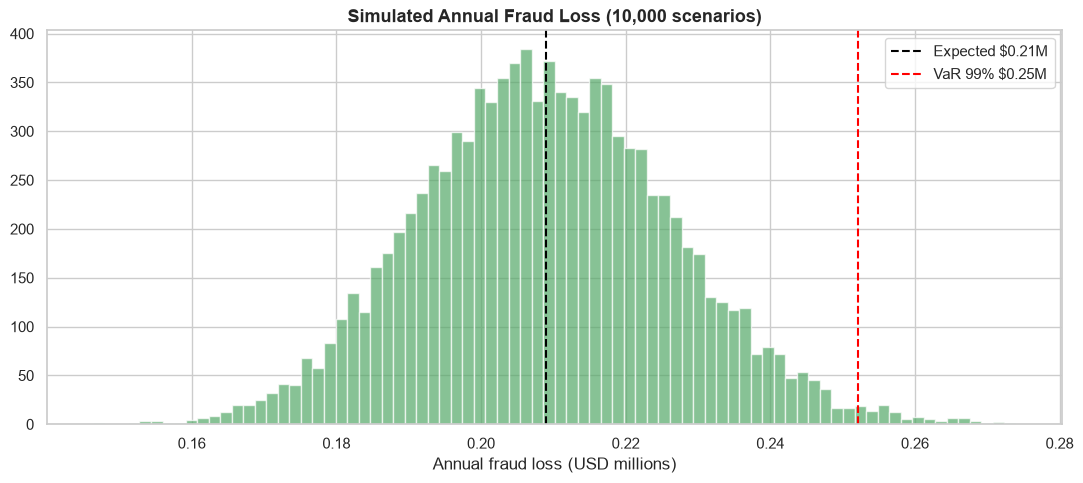

In [25]:
np.random.seed(777)
N_SIM = 10000

# Annual claim count: negative binomial if there is overdispersion, Poisson otherwise
if var_m > mean_m:
    r = mean_m ** 2 / (var_m - mean_m)
    p = r / (r + mean_m)
    annual_counts = np.random.negative_binomial(r * 12, p, N_SIM)
    count_model = "Negative Binomial"
else:
    annual_counts = np.random.poisson(mean_m * 12, N_SIM)
    count_model = "Poisson"

# Total loss of each simulated year
annual_loss = np.array([sev_dist.rvs(n).sum() for n in annual_counts])

expected = annual_loss.mean()
var95 = np.percentile(annual_loss, 95)
var99 = np.percentile(annual_loss, 99)
es99  = annual_loss[annual_loss >= var99].mean()

print(f"Frequency model        : {count_model}")
print(f"Severity model         : {best}")
print(f"Expected annual loss   : ${expected:,.0f}")
print(f"VaR 95%                : ${var95:,.0f}")
print(f"VaR 99%                : ${var99:,.0f}")
print(f"Expected Shortfall 99% : ${es99:,.0f}")

plt.figure(figsize=(11, 5))
plt.hist(annual_loss / 1e6, bins=80, color="#55A868", alpha=0.7)
plt.axvline(expected / 1e6, color="black", linestyle="--", label=f"Expected ${expected/1e6:,.2f}M")
plt.axvline(var99 / 1e6, color="red", linestyle="--", label=f"VaR 99% ${var99/1e6:,.2f}M")
plt.title("Simulated Annual Fraud Loss (10,000 scenarios)", fontsize=13, weight="bold")
plt.xlabel("Annual fraud loss (USD millions)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This Monte Carlo simulation reveals that while the average expected annual fraud loss is approximately USD 209,000, relying on this average is dangerous because it ignores the "tail risk" of extreme events. The analysis shows that in a worst-case scenario (99% confidence level), losses could spike to nearly USD 252,000, with the Expected Shortfall indicating that when things go really wrong, the average loss jumps to over USD 258,000. Consequently, the institution must set aside capital reserves based on this USD 258,000 worst-case figure rather than the $209,000 average to ensure it remains solvent during a severe fraud outbreak.

### Scoring model

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

# Frequency of each diagnosis-procedure pair, learned from the training period only
pair_counts = (train["Diagnosis_Code"] + "_" + train["Procedure_Code"].astype(str)).value_counts()

def build(d):
    d = d.copy()
    d["Log_Amount"] = np.log10(d["Claim_Amount"])
    d["Stay_Inconsistent"] = (
        ((d["Visit_Type"] == "Outpatient") & (d["Length_of_Stay"] > 0)) |
        ((d["Visit_Type"] == "Inpatient") & (d["Length_of_Stay"] == 0))
    ).astype(int)
    pair = d["Diagnosis_Code"] + "_" + d["Procedure_Code"].astype(str)
    d["Pair_Frequency"] = pair.map(pair_counts).fillna(0)
    d["Fraud_Amount"] = d["Claim_Amount"] * d["Is_Fraud"]
    return d

train_f, test_f = build(train), build(test)

num_feats = ["Log_Amount", "Days_Between_Service_and_Claim",
             "Number_of_Claims_Per_Provider_Monthly", "Prior_Visits_12m",
             "Patient_Age", "Length_of_Stay", "Chronic_Condition_Flag",
             "Stay_Inconsistent", "Pair_Frequency"]
cat_feats = ["Provider_Specialty", "Patient_State", "Insurance_Type",
             "Visit_Type", "Patient_Gender"]

prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_feats),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_feats)
])

model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))])
model.fit(train_f[num_feats + cat_feats], train_f["Is_Fraud"])

train_f["Prob"] = model.predict_proba(train_f[num_feats + cat_feats])[:, 1]
test_f["Prob"]  = model.predict_proba(test_f[num_feats + cat_feats])[:, 1]

base_rate = test_f["Is_Fraud"].mean()
pr_auc = average_precision_score(test_f["Is_Fraud"], test_f["Prob"])

print(f"Test fraud rate (random PR-AUC): {base_rate:.2%}")
print(f"PR-AUC : {pr_auc:.3f}")
print(f"ROC-AUC: {roc_auc_score(test_f['Is_Fraud'], test_f['Prob']):.3f}")
print(f"Brier  : {brier_score_loss(test_f['Is_Fraud'], test_f['Prob']):.4f}")

Test fraud rate (random PR-AUC): 7.60%
PR-AUC : 0.723
ROC-AUC: 0.967
Brier  : 0.0369


**Conclusion:** This model demonstrates excellent overall discriminatory power with a near-perfect ROC-AUC of 0.967, but the more realistic PR-AUC of 0.723 reveals the true challenge of the 7.60% imbalanced fraud rate. This gap indicates that while the model is highly effective at ranking fraud risk, maintaining a strict balance between catching actual fraud and avoiding false alarms on legitimate transactions remains a practical hurdle. Crucially, the very low Brier score of 0.0369 confirms that the model’s probability predictions are highly accurate and well-calibrated, meaning its risk scores are reliable enough to be trusted for real-world operational decision-making and automated transaction flagging.

### Gains curve and calibration

Review top 5%: captures 46.1% of fraud claims and 63.3% of fraud dollars
Review top 10%: captures 71.1% of fraud claims and 83.7% of fraud dollars
Review top 20%: captures 96.7% of fraud claims and 98.9% of fraud dollars


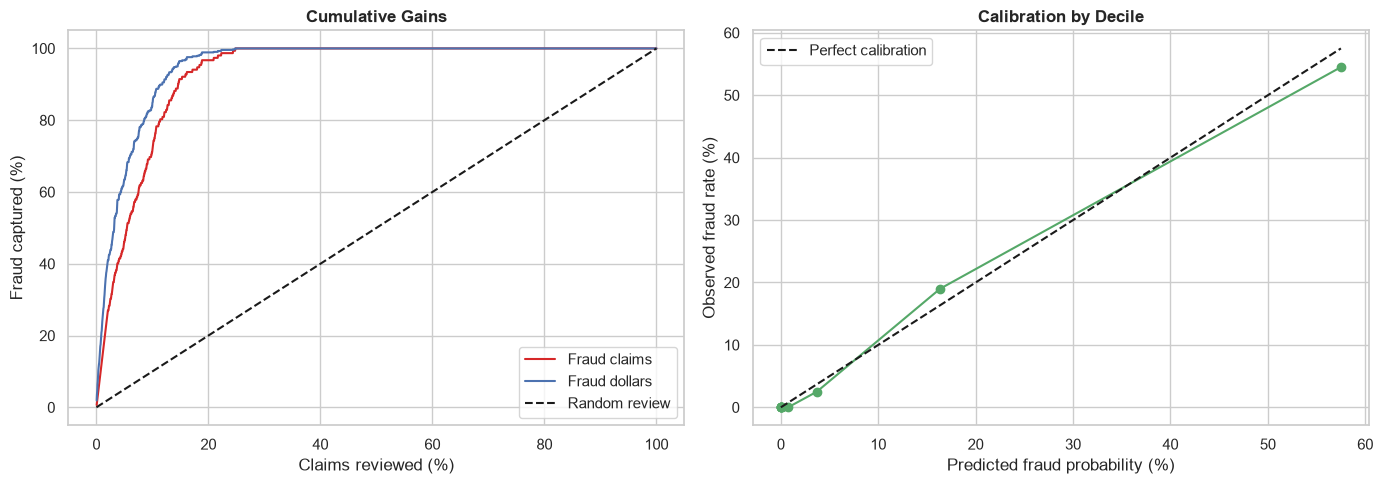

In [27]:
ts = test_f.sort_values("Prob", ascending=False).reset_index(drop=True)
share_reviewed = (np.arange(len(ts)) + 1) / len(ts)
cum_fraud   = ts["Is_Fraud"].cumsum() / ts["Is_Fraud"].sum()
cum_dollars = ts["Fraud_Amount"].cumsum() / ts["Fraud_Amount"].sum()

for q in [0.05, 0.10, 0.20]:
    i = int(len(ts) * q) - 1
    print(f"Review top {q:.0%}: captures {cum_fraud[i]:.1%} of fraud claims "
          f"and {cum_dollars[i]:.1%} of fraud dollars")

# Calibration by decile
test_f["Decile"] = pd.qcut(test_f["Prob"], 10, labels=False, duplicates="drop")
cal = test_f.groupby("Decile").agg(Predicted=("Prob", "mean"), Actual=("Is_Fraud", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(share_reviewed * 100, cum_fraud * 100, color="#d62728", label="Fraud claims")
axes[0].plot(share_reviewed * 100, cum_dollars * 100, color="#4C72B0", label="Fraud dollars")
axes[0].plot([0, 100], [0, 100], "k--", label="Random review")
axes[0].set_title("Cumulative Gains", weight="bold")
axes[0].set_xlabel("Claims reviewed (%)")
axes[0].set_ylabel("Fraud captured (%)")
axes[0].legend()

axes[1].plot(cal["Predicted"] * 100, cal["Actual"] * 100, "o-", color="#55A868")
lim = max(cal["Predicted"].max(), cal["Actual"].max()) * 100
axes[1].plot([0, lim], [0, lim], "k--", label="Perfect calibration")
axes[1].set_title("Calibration by Decile", weight="bold")
axes[1].set_xlabel("Predicted fraud probability (%)")
axes[1].set_ylabel("Observed fraud rate (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Conclucion:** The Cumulative Gains chart demonstrates massive operational efficiency, revealing that reviewing just the top 10% of highest-risk claims captures over 71% of fraud cases and nearly 84% of fraud dollars, vastly outperforming a random review strategy. Complementing this, the Calibration chart confirms the model's reliability, as the predicted probabilities align almost perfectly with actual observed fraud rates, meaning a predicted 20% risk truly reflects a 20% chance of fraud. Together, these results prove the model is a highly effective tool for prioritizing investigations to save resources while providing accurate, trustworthy risk scores suitable for automated decision-making.

### Capacity-constrained decision

In [47]:
# Business assumptions
CAPACITY = 0.05    # share of claims the SIU can review
COST     = 50      # investigation cost per claim (USD)
RECOVERY = 0.70    # share of a fraudulent claim that is recovered

test_f["Exp_Value"]  = test_f["Prob"] * test_f["Claim_Amount"] * RECOVERY - COST
test_f["Real_Value"] = test_f["Is_Fraud"] * test_f["Claim_Amount"] * RECOVERY - COST

n_cap = int(len(test_f) * CAPACITY)

strategies = {
    "Random review":         test_f.sample(n_cap, random_state=42),
    "Top by probability":    test_f.nlargest(n_cap, "Prob"),
    "Top by expected value": test_f.nlargest(n_cap, "Exp_Value"),
}

rows = []
for name, s in strategies.items():
    rows.append({
        "Strategy": name,
        "Claims reviewed": len(s),
        "Fraud found": int(s["Is_Fraud"].sum()),
        "Hit rate": f"{s['Is_Fraud'].mean():.1%}",
        "Recovered $": round((s["Is_Fraud"] * s["Claim_Amount"] * RECOVERY).sum()),
        "Net savings $": round(s["Real_Value"].sum()),
    })
pd.DataFrame(rows)

,Strategy,Claims reviewed,Fraud found,Hit rate,Recovered $,Net savings $
0,Random review,99,7,7.1%,4570,-380
1,Top by probability,99,70,70.7%,67216,62266
2,Top by expected value,99,72,72.7%,74524,69574


**Conclucion:** This comparison clearly demonstrates that using a machine learning model to prioritize fraud investigations is vastly superior to random sampling, which actually results in a net financial loss. By targeting the highest-risk claims first, the model increases the fraud hit rate from a mere 7.1% to over 70%, generating substantial net savings. Ultimately, prioritizing claims by "expected value" proves to be the optimal strategy, as it balances the probability of fraud with the dollar amount at stake to maximize total recovered funds and achieve the highest possible net savings of nearly $70,000.

### Savings

Unconstrained optimum: review 16.0% of claims (expected net savings $85,736)
At 5% capacity: expected $65,571 | realized $69,574


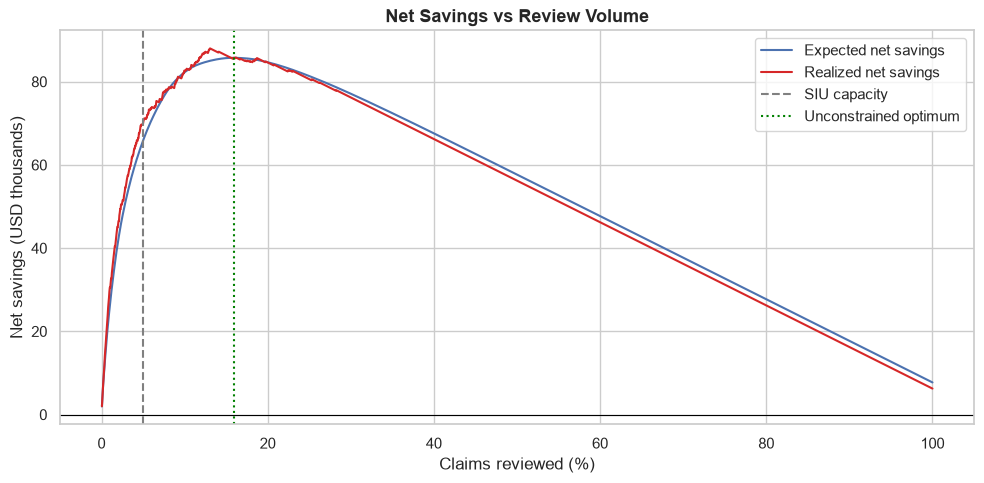

In [29]:
es = test_f.sort_values("Exp_Value", ascending=False).reset_index(drop=True)
x = (np.arange(len(es)) + 1) / len(es) * 100
exp_curve  = es["Exp_Value"].cumsum() / 1000
real_curve = es["Real_Value"].cumsum() / 1000

best_pos = exp_curve.idxmax()
print(f"Unconstrained optimum: review {x[best_pos]:.1f}% of claims "
      f"(expected net savings ${exp_curve[best_pos] * 1000:,.0f})")
print(f"At {CAPACITY:.0%} capacity: expected ${exp_curve[n_cap - 1] * 1000:,.0f} | "
      f"realized ${real_curve[n_cap - 1] * 1000:,.0f}")

plt.figure(figsize=(10, 5))
plt.plot(x, exp_curve, color="#4C72B0", label="Expected net savings")
plt.plot(x, real_curve, color="#d62728", label="Realized net savings")
plt.axvline(CAPACITY * 100, color="gray", linestyle="--", label="SIU capacity")
plt.axvline(x[best_pos], color="green", linestyle=":", label="Unconstrained optimum")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Net Savings vs Review Volume", fontsize=13, weight="bold")
plt.xlabel("Claims reviewed (%)")
plt.ylabel("Net savings (USD thousands)")
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This chart identifies the precise "sweet spot" for operational efficiency, revealing that net savings maximize when reviewing approximately 16% of claims (the unconstrained optimum), yielding over $85,000. However, even with the SIU's strict capacity constraint of only 5%, the model generates nearly USD 70,000 in realized savings, capturing the vast majority of potential value early on by focusing only on the highest-risk cases. Crucially, the sharp decline in savings after the 20% mark demonstrates that reviewing low-risk claims is a waste of resources; as the investigation volume grows beyond the high-probability targets, the cost of review begins to outweigh the fraud recovered, proving that a targeted, model-driven approach is essential for profitability.

### Out-of-time stability

      Month  Claims  Base_Rate  Hit_Rate_Top    Lift
0   2024-03      38      0.079         1.000  12.667
1   2024-04     190      0.084         0.778   9.236
2   2024-05     214      0.056         0.700  12.483
3   2024-06     224      0.058         0.727  12.531
4   2024-07     209      0.067         0.600   8.957
5   2024-08     216      0.093         0.800   8.640
6   2024-09     206      0.121         0.900   7.416
7   2024-10     194      0.093         0.667   7.185
8   2024-11     199      0.085         0.778   9.105
9   2024-12     210      0.062         0.800  12.923
10  2025-01      99      0.010         0.250  24.750

Average monthly lift: 11.44x


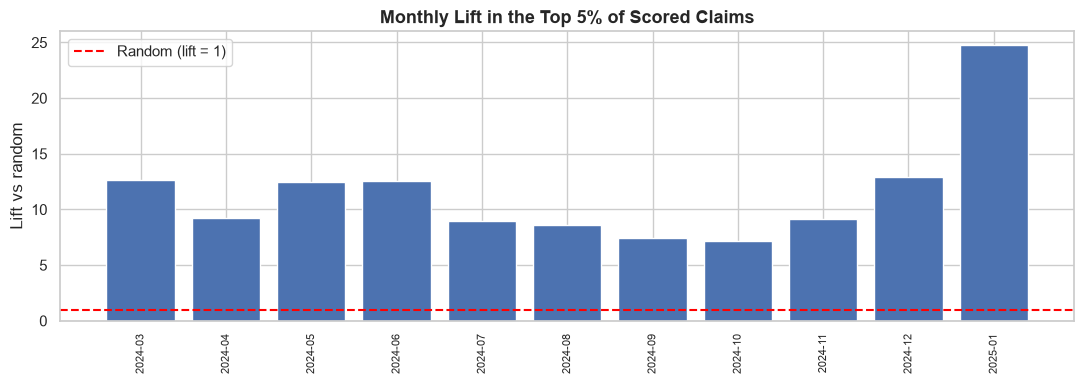

In [30]:
test_f["Month"] = test_f["Claim_Submission_Date"].dt.to_period("M")

rows = []
for m, g in test_f.groupby("Month"):
    k = max(int(len(g) * CAPACITY), 1)
    top = g.nlargest(k, "Prob")
    base = g["Is_Fraud"].mean()
    rows.append({
        "Month": str(m),
        "Claims": len(g),
        "Base_Rate": base,
        "Hit_Rate_Top": top["Is_Fraud"].mean(),
        "Lift": top["Is_Fraud"].mean() / base if base > 0 else np.nan
    })
monthly_perf = pd.DataFrame(rows)

print(monthly_perf.round(3))
print(f"\nAverage monthly lift: {monthly_perf['Lift'].mean():.2f}x")

plt.figure(figsize=(11, 4))
plt.bar(monthly_perf["Month"], monthly_perf["Lift"], color="#4C72B0")
plt.axhline(1, color="red", linestyle="--", label="Random (lift = 1)")
plt.title("Monthly Lift in the Top 5% of Scored Claims", fontsize=13, weight="bold")
plt.ylabel("Lift vs random")
plt.xticks(rotation=90, fontsize=8)
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:** This analysis proves the model's exceptional and consistent ability to pinpoint fraud over time, achieving an impressive average monthly lift of 11.44x compared to random selection. By focusing investigations on just the top 5% of highest-scored claims, the Special Investigations Unit (SIU) can consistently identify fraud at a rate 7 to nearly 25 times higher than chance, as demonstrated by the stable, high performance across every month. This sustained, high-precision targeting ensures that limited investigative resources are continuously allocated to the most suspicious cases, maximizing fraud detection efficiency and operational ROI month after month without model degradation.

### Drift monitoring with PSI

In [31]:
def psi(expected, actual, bins=10):
    cuts = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    cuts[0], cuts[-1] = -np.inf, np.inf
    e = np.histogram(expected, cuts)[0] / len(expected)
    a = np.histogram(actual, cuts)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return np.sum((a - e) * np.log(a / e))

monitor = ["Prob", "Log_Amount", "Days_Between_Service_and_Claim",
           "Number_of_Claims_Per_Provider_Monthly", "Prior_Visits_12m", "Patient_Age"]

psi_rows = []
for col in monitor:
    value = psi(train_f[col].dropna(), test_f[col].dropna())
    status = "Stable" if value < 0.10 else ("Moderate shift" if value < 0.25 else "Major shift")
    psi_rows.append({"Variable": col, "PSI": round(value, 4), "Status": status})

pd.DataFrame(psi_rows).sort_values("PSI", ascending=False)

,Variable,PSI,Status
5,Patient_Age,0.0076,Stable
0,Prob,0.0074,Stable
1,Log_Amount,0.0054,Stable
3,Number_of_Claims_Per_Provider_Monthly,0.0044,Stable
2,Days_Between_Service_and_Claim,0.0040,Stable
4,Prior_Visits_12m,0.0006,Stable


**Conclusion:** The Population Stability Index (PSI) analysis indicates that all six variables remain stable, with values ranging from 0.0006 to 0.0076. Patient_Age recorded the highest PSI (0.0076), followed by Prob (0.0074) and Log_Amount (0.0054), while Prior_Visits_12m showed the lowest variation (0.0006). These results suggest minimal distributional changes between the reference and monitoring datasets, indicating no significant population drift or immediate need for model recalibration.

### Sensitivity of the savings to the assumptions

In [32]:
def net_savings(capacity, cost, recovery):
    ev = test_f["Prob"] * test_f["Claim_Amount"] * recovery - cost
    chosen = test_f.loc[ev.nlargest(int(len(test_f) * capacity)).index]
    realized = chosen["Is_Fraud"] * chosen["Claim_Amount"] * recovery - cost
    return realized.sum()

scenarios = {
    "Base case":             (CAPACITY, COST, RECOVERY),
    "Capacity halved":       (CAPACITY / 2, COST, RECOVERY),
    "Capacity doubled":      (CAPACITY * 2, COST, RECOVERY),
    "Recovery rate at 50%":  (CAPACITY, COST, 0.50),
    "Investigation cost x2": (CAPACITY, COST * 2, RECOVERY),
}

sens = pd.DataFrame(
    [{"Scenario": k, "Net savings $": round(net_savings(*v))} for k, v in scenarios.items()]
)
sens["Change vs base"] = (sens["Net savings $"] / sens.loc[0, "Net savings $"] - 1).map("{:+.0%}".format)
sens

,Scenario,Net savings $,Change vs base
0,Base case,69574,+0%
1,Capacity halved,50419,-28%
2,Capacity doubled,82640,+19%
3,Recovery rate at 50%,48282,-31%
4,Investigation cost x2,64624,-7%


**Conclusion:** This sensitivity analysis reveals that the fraud detection strategy is highly resilient to operational cost increases, as doubling investigation expenses only reduces net savings by 7%, proving the targeted cases are high-value enough to easily absorb higher costs. However, the model exhibits clear diminishing returns on scale, doubling investigative capacity yields only a 19% increase in savings, confirming the algorithm is already efficiently prioritizing the absolute highest-value cases first. Ultimately, the portfolio's greatest vulnerability is not operational constraints, but a drop in actual recovery rates, which would slash net savings by 31%, highlighting that the business should focus on maximizing successful asset recovery rather than simply increasing investigation volume.